# MLP: train and validate on log power spectra

This notebook follows one experiment from loading data to evaluating predictions. Each code cell has an explanation of its purpose and the checks to expect.

**Inputs:** 50 saved log-power features per map. **Targets:** `[Omega_m, sigma_8]`. We load spectra directly; training needs no images or FFT.

The default experiment uses **level 1, validation fold 5**: 660 training maps from 44 simulations and 150 validation maps from 10 simulations. The 15 maps from a simulation share the same targets and must stay together. Levels 1, 2, and 3 are disjoint datasets.

### How to run

1. Select the project **`.venv/bin/python`** kernel in VS Code.
2. Run cells from top to bottom. After editing an imported module, restart the kernel and run all cells.
3. After changing the settings, rerun all cells so the split, scalers, and model agree.

The model-creation cell resets weights and the optimizer. Rerunning only the training cell continues from the current weights; its history and best-checkpoint tracking start again. For a fresh comparable experiment, rerun all cells.

**Evaluation boundary:** this is one development-fold experiment. Validation selects the best checkpoint. Test data is never loaded. Results here are validation results, not final test performance. The original learning script remains available as `check_data.py`.


## 1. Find the project folder

Notebooks do not define `__file__`. This cell searches the current folder and its parents for `mlp/data.py`, then makes the project modules importable. It works when launched from the project root, `mlp/`, or `mlp/level1/`.

**Check:** the printed path should end in `cosmoreg`.

In [1]:
# Locate the project when the notebook runs from the root or mlp folder.
from pathlib import Path
import sys

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "mlp" / "data.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open VS Code in the cosmoreg project folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)


Project root: /home/meatpigeon/Personal/classes/csci494/cosmoreg


## 2. Imports and experiment settings

Keep the experiment choices together. `LEVEL` chooses the dataset; `VALIDATION_FOLD` chooses which development fold is held out. The other four folds provide training data. The seed controls PyTorch initialization and batch shuffling for this run.

The starting model uses AdamW with a learning rate of `0.001`, weight decay of `0.0001`, batches of 64, and 20 epochs. These settings are a starting experiment, not a demonstrated optimum.

In [2]:
from copy import deepcopy

import numpy as np
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from mlp import data
from mlp.model import SpectrumMLP
from mlp.train import train_one_epoch
from mlp.evaluate import evaluate_loss, average_by_simulation

LEVEL_ROOT = PROJECT_ROOT / "mlp" / "level1"
SPECTRA_ROOT = PROJECT_ROOT / "powerspectrum"
LEVEL = 1
VALIDATION_FOLD = 5
SEED = 42
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

assert LEVEL in (1, 2, 3)
assert VALIDATION_FOLD in range(1, 6)


## 3. Load the split and check simulation separation

`X` contains inputs, `y` contains the two correct answers per map, and `ids` identifies each map's simulation. Rows are samples; columns are features or targets.

```text
X shape = (number_of_maps, 50)
y shape = (number_of_maps, 2)
ids shape = (number_of_maps,)
```

The last assertion checks that no simulation appears in both training and validation. Splitting related maps across these groups would leak information and make validation misleading.

In [3]:
X_train, y_train, ids_train, X_val, y_val, ids_val = (
    data.load_train_validation(SPECTRA_ROOT, LEVEL, VALIDATION_FOLD)
)

assert X_train.ndim == X_val.ndim == 2
assert X_train.shape[1] == X_val.shape[1] == 50
assert y_train.shape == (X_train.shape[0], 2)
assert y_val.shape == (X_val.shape[0], 2)
assert ids_train.shape == (X_train.shape[0],)
assert ids_val.shape == (X_val.shape[0],)
assert np.intersect1d(ids_train, ids_val).size == 0, "Simulation leakage!"

print("Training shapes:", X_train.shape, y_train.shape, ids_train.shape)
print("Validation shapes:", X_val.shape, y_val.shape, ids_val.shape)
print("Unique simulations:", len(np.unique(ids_train)), "train,",
      len(np.unique(ids_val)), "validation")
print("Loading and split checks passed.")


Training shapes: (660, 50) (660, 2) (660,)
Validation shapes: (150, 50) (150, 2) (150,)
Unique simulations: 44 train, 10 validation
Loading and split checks passed.


## 4. Standardize the input features

Each feature column gets its own mean and standard deviation, fitted using **training rows only**. Apply those same values to validation. The log transform already saved in the data is separate from this step.

```text
scaled_feature = (feature - training_mean) / training_std
```

**Check:** nonconstant training columns have mean near 0 and standard deviation near 1. Validation need not have either property. The helper replaces a zero standard deviation with 1 to avoid division by zero.

In [4]:
feature_mean, feature_std = data.fit_feature_scaler(X_train)
assert feature_mean.shape == feature_std.shape == (50,)
assert np.isfinite(feature_mean).all()
assert np.isfinite(feature_std).all()
assert np.all(feature_std > 0)

X_train_scaled = data.transform_features(X_train, feature_mean, feature_std)
X_val_scaled = data.transform_features(X_val, feature_mean, feature_std)

assert X_train_scaled.shape == X_train.shape
assert X_val_scaled.shape == X_val.shape
assert np.allclose(X_train_scaled.mean(axis=0), 0, atol=1e-5)
nonconstant_features = X_train.std(axis=0) > 0
assert np.allclose(
    X_train_scaled.std(axis=0)[nonconstant_features], 1, atol=1e-5
)
print("Feature scaling checks passed.")


Feature scaling checks passed.


## 5. Standardize targets and check the inverse transform

Scale `Omega_m` and `sigma_8` separately using their training statistics. This gives both targets comparable scales in the training loss. Validation reuses the training statistics.

```text
scaled_target = (target - training_mean) / training_std
target = scaled_target * training_std + training_mean
```

**Check:** inverse transformation recovers the original training targets. We use this same inverse operation later to report errors in original units.

In [5]:
target_mean, target_std = data.fit_target_scaler(y_train)
assert target_mean.shape == target_std.shape == (2,)
assert np.isfinite(target_mean).all()
assert np.isfinite(target_std).all()
assert np.all(target_std > 0)

y_train_scaled = data.transform_targets(y_train, target_mean, target_std)
y_val_scaled = data.transform_targets(y_val, target_mean, target_std)

assert y_train_scaled.shape == y_train.shape
assert y_val_scaled.shape == y_val.shape
assert np.allclose(y_train_scaled.mean(axis=0), 0, atol=1e-5)
nonconstant_targets = y_train.std(axis=0) > 0
assert np.allclose(
    y_train_scaled.std(axis=0)[nonconstant_targets], 1, atol=1e-5
)

y_restored = data.inverse_transform_targets(y_train_scaled, target_mean, target_std)
assert np.allclose(y_restored, y_train, rtol=1e-5, atol=1e-6)
print("Target scaling and inverse transformation checks passed.")


Target scaling and inverse transformation checks passed.


## 6. Convert NumPy arrays to PyTorch tensors

The scaling helpers return `float32` arrays, which match the model's default weight type. `torch.from_numpy` creates tensors from these arrays without changing their shape; it shares their underlying memory.

**Check:** all four tensors are finite and have dtype `torch.float32`. Training has not started yet.

In [6]:
X_train_tensor = torch.from_numpy(X_train_scaled)
y_train_tensor = torch.from_numpy(y_train_scaled)
X_val_tensor = torch.from_numpy(X_val_scaled)
y_val_tensor = torch.from_numpy(y_val_scaled)

for tensor in (X_train_tensor, y_train_tensor, X_val_tensor, y_val_tensor):
    assert tensor.dtype == torch.float32
    assert torch.isfinite(tensor).all().item()

print("Training tensors:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation tensors:", X_val_tensor.shape, y_val_tensor.shape)
print("All data checks passed. No model training has been run.")


Training tensors: torch.Size([660, 50]) torch.Size([660, 2])
Validation tensors: torch.Size([150, 50]) torch.Size([150, 2])
All data checks passed. No model training has been run.


## 7. Pair each input with its target

`TensorDataset` keeps the input and target at the same row together. For example, `train_dataset[0]` returns one 50-feature spectrum and its two targets. Shuffling later moves the pair together.

**Check:** the dataset length equals the number of training maps; its first pair matches the first rows of the training tensors.

In [ ]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

sample_X, sample_y = train_dataset[0]

print("Training dataset size:", len(train_dataset))
print("One input shape:", sample_X.shape)
print("One target shape:", sample_y.shape)

assert len(train_dataset) == X_train_tensor.shape[0]
assert torch.equal(sample_X, X_train_tensor[0])
assert torch.equal(sample_y, y_train_tensor[0])


Training dataset size: 660
One input shape: torch.Size([50])
One target shape: torch.Size([2])


## 8. Create training batches

`DataLoader` supplies batches rather than all maps at once. Training shuffles the sample order each epoch. A batch has up to `BATCH_SIZE` rows; the last batch may be smaller.

The preview shows shapes only. It does not update the model. The training helper weights batch losses by their number of target values so a smaller last batch is counted correctly.

In [8]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

batch_X, batch_y = next(iter(train_loader))

print("Input batch:", batch_X.shape)
print("Target batch:", batch_y.shape)

assert batch_X.shape == (min(BATCH_SIZE, len(train_dataset)), 50)
assert batch_y.shape == (min(BATCH_SIZE, len(train_dataset)), 2)


Input batch: torch.Size([64, 50])
Target batch: torch.Size([64, 2])


## 9. Create validation batches

Validation uses `shuffle=False`, preserving row order. Validation measures predictions without updating weights. `evaluate_loss` uses both `model.eval()` and `torch.no_grad()`: evaluation mode sets layer behavior, while `no_grad()` disables gradient tracking.

**Check:** each validation batch pairs 50-feature inputs with two targets.

In [9]:
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

val_batch_X, val_batch_y = next(iter(val_loader))

print("Validation input batch:", val_batch_X.shape)
print("Validation target batch:", val_batch_y.shape)

assert val_batch_X.shape == (min(BATCH_SIZE, len(val_dataset)), 50)
assert val_batch_y.shape == (min(BATCH_SIZE, len(val_dataset)), 2)


Validation input batch: torch.Size([64, 50])
Validation target batch: torch.Size([64, 2])


## 10. Create a fresh model, loss, and optimizer

The compact MLP has architecture `50 -> 32 -> 16 -> 2`, with ReLU between hidden layers and two linear outputs. It has **2,194 trainable parameters**. Outputs predict standardized targets. With only 44 independent training simulations in the default split, this is a reasonable starting size to investigate.

`MSELoss` averages squared errors over both target columns. AdamW updates the weights using gradients computed during training.

**Rerun behavior:** this cell resets the model and optimizer. The shape check makes a forward pass without updating weights.

In [10]:
torch.manual_seed(SEED)
model = SpectrumMLP()
loss_fn = nn.MSELoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

with torch.no_grad():
    predictions = model(batch_X)

parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print("Prediction shape:", predictions.shape)
print("Trainable parameters:", parameter_count)

assert predictions.shape == batch_y.shape
assert torch.isfinite(predictions).all().item()
assert parameter_count == 2194


SpectrumMLP(
  (network): Sequential(
    (0): Linear(in_features=50, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=2, bias=True)
  )
)
Prediction shape: torch.Size([64, 2])
Trainable parameters: 2194


## 11. Train and keep the best validation checkpoint

An epoch visits all training batches once. Within each batch, `train_one_epoch` clears old gradients, predicts, computes MSE, calls `backward()` to calculate gradients, and calls `step()` to update weights. Validation follows each epoch without updates.

Training MSE combines losses measured as the weights change throughout the epoch. Validation MSE measures the fixed model at the end of the epoch, so they are not exactly the same measurement.

When validation MSE improves, `deepcopy` saves an independent copy of the weights. We run all configured epochs, then choose the best checkpoint; there is no early stopping. Rerunning this cell resets histories and checkpoint tracking but continues training the current model.

In [11]:
best_val_loss = float("inf")
best_epoch = None
best_state = None

train_history = []
val_history = []

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)

    val_loss = evaluate_loss(model, val_loader, loss_fn)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = deepcopy(model.state_dict())

    train_history.append(train_loss)
    val_history.append(val_loss)

    print(
        f"Epoch {epoch:02d} | "
        f"Train MSE: {train_loss:.4f} | "
        f"Validation MSE: {val_loss:.4f}"
    )


Epoch 01 | Train MSE: 0.9041 | Validation MSE: 1.2382
Epoch 02 | Train MSE: 0.7955 | Validation MSE: 1.2305
Epoch 03 | Train MSE: 0.7520 | Validation MSE: 1.1970
Epoch 04 | Train MSE: 0.7289 | Validation MSE: 1.1873
Epoch 05 | Train MSE: 0.7126 | Validation MSE: 1.2024
Epoch 06 | Train MSE: 0.7068 | Validation MSE: 1.2041
Epoch 07 | Train MSE: 0.7017 | Validation MSE: 1.1862
Epoch 08 | Train MSE: 0.6980 | Validation MSE: 1.1935
Epoch 09 | Train MSE: 0.6941 | Validation MSE: 1.1971
Epoch 10 | Train MSE: 0.6904 | Validation MSE: 1.1788
Epoch 11 | Train MSE: 0.6899 | Validation MSE: 1.1888
Epoch 12 | Train MSE: 0.6874 | Validation MSE: 1.1776
Epoch 13 | Train MSE: 0.6852 | Validation MSE: 1.1788
Epoch 14 | Train MSE: 0.6837 | Validation MSE: 1.1850
Epoch 15 | Train MSE: 0.6813 | Validation MSE: 1.1657
Epoch 16 | Train MSE: 0.6801 | Validation MSE: 1.1689
Epoch 17 | Train MSE: 0.6785 | Validation MSE: 1.1646
Epoch 18 | Train MSE: 0.6755 | Validation MSE: 1.1517
Epoch 19 | Train MSE: 0.6742

## 12. Restore the best checkpoint

The last epoch may perform worse than an earlier one. Restore the saved weights before evaluating. `best_epoch` is counted within the training run immediately above.

**Check:** reevaluating the restored model should reproduce the lowest recorded validation MSE. The checkpoint lives in memory; this notebook does not yet save a reusable model and scalers to disk.

In [12]:
model.load_state_dict(best_state)
val_loss = evaluate_loss(model, val_loader, loss_fn)

assert np.isclose(val_loss, best_val_loss), \
    "Restored model loss does not match the best recorded loss."

print("Restored best epoch:", best_epoch)
print("Best model validation MSE:", val_loss)


Restored best epoch: 18
Best model validation MSE: 1.151694564819336


## 13. Compare with the training-mean baseline

A useful reference always predicts the training mean for each target, ignoring the spectrum. It has no layers, optimizer, or training epochs. In standardized target space, the training means become `[0, 0]`, so zeros implement this predictor.

A lower validation MSE than this baseline shows improvement on this split. It does not establish performance on the untouched test set.

In [13]:
baseline_predictions = torch.zeros_like(y_val_tensor)

with torch.no_grad():
    baseline_loss = loss_fn(baseline_predictions, y_val_tensor)

print("Training-mean baseline MSE:", baseline_loss.item())
print("Model validation MSE:", val_loss)

if val_loss < baseline_loss.item():
    print("The model beats the training-mean baseline.")
else:
    print("The model does not yet beat the training-mean baseline.")


Training-mean baseline MSE: 1.242409586906433
Model validation MSE: 1.151694564819336
The model beats the training-mean baseline.


## 14. Inspect the learning curves

The curves show how training and validation MSE change with epoch; the dashed line is the constant baseline. A widening gap can suggest fitting training-specific patterns, but one small validation fold is not enough to diagnose the cause confidently.

The figure is displayed in the notebook and saved as `mlp_learning_curves.png` in `mlp/level1/`. Rerunning this cell replaces that image.

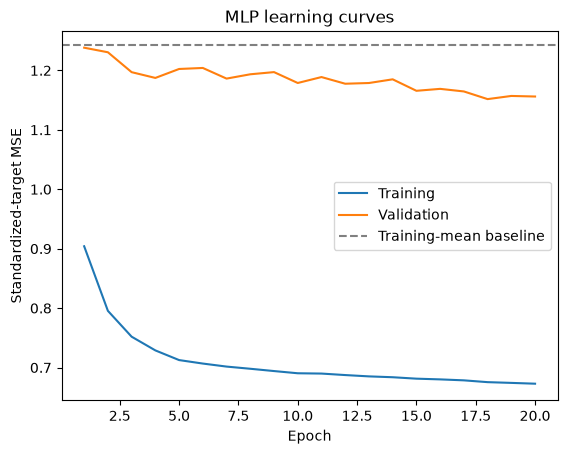

Plot saved to: /home/meatpigeon/Personal/classes/csci494/cosmoreg/mlp/level1/mlp_learning_curves.png


In [14]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_history) + 1)

fig, ax = plt.subplots()

ax.plot(epochs, train_history, label="Training")

ax.plot(epochs, val_history, label="Validation")

ax.axhline(
    baseline_loss.item(),
    color="gray",
    linestyle="--",
    label="Training-mean baseline",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Standardized-target MSE")
ax.set_title("MLP learning curves")
ax.legend()

figure_path = LEVEL_ROOT / "mlp_learning_curves.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Plot saved to:", figure_path)


## 15. Measure map-level error in original units

Predict the complete validation set with the restored model, then undo target scaling. Calculate errors separately for the two target columns (`axis=0`).

```text
error = prediction - target
RMSE = sqrt(mean(error**2))
MAE = mean(abs(error))
```

RMSE gives larger errors more weight; MAE measures average absolute error. Both are in the original target units. Here every map contributes one error, but maps from the same simulation are related.

In [15]:
model.eval()

with torch.no_grad():
    predictions_scaled = model(X_val_tensor).numpy()

predictions_original = data.inverse_transform_targets(
    predictions_scaled, target_mean, target_std
)

errors = predictions_original - y_val

rmse = np.sqrt(np.mean(errors**2, axis=0))

mae = np.mean(np.abs(errors), axis=0)

target_names = ["Omega_m", "sigma_8"]

for i, name in enumerate(target_names):
    print(f"{name}: RMSE={rmse[i]:.4f}, MAE={mae[i]:.4f}")


Omega_m: RMSE=0.1192, MAE=0.1068
sigma_8: RMSE=0.1090, MAE=0.0945


## 16. Compare map-level RMSE with the baseline

The original-unit baseline is `target_mean`, fitted earlier using training data. Compare RMSE separately for each target, since improvement can differ between them.

```text
RMSE improvement (%) = 100 * (1 - model_RMSE / baseline_RMSE)
```

Positive values mean lower error than the baseline; negative values mean higher error. A zero baseline RMSE makes the percentage undefined.

In [16]:
baseline_errors = target_mean - y_val
baseline_rmse = np.sqrt(np.mean(baseline_errors ** 2, axis=0))

for i, name in enumerate(target_names):
    improvement = (
        100 * (1 - rmse[i] / baseline_rmse[i])
        if baseline_rmse[i] > 0 else float("nan")
    )
    print(
        f"{name}: baseline RMSE={baseline_rmse[i]:.4f}, "
        f"MLP RMSE={rmse[i]:.4f}, RMSE improvement={improvement:.1f}%"
    )


Omega_m: baseline RMSE=0.1203, MLP RMSE=0.1192, RMSE improvement=1.0%
sigma_8: baseline RMSE=0.1176, MLP RMSE=0.1090, RMSE improvement=7.3%


## 17. Average predictions within each simulation

Each simulation has one shared target pair and 15 related maps. Group the predictions across the **whole validation set**, then average each simulation's map predictions. We average predictions here, not maps or input spectra.

**Check:** one output row remains per validation simulation, each mean matches its map predictions, and all targets within the simulation agree. The default split gives 10 rows.

In [17]:
sim_predictions, sim_targets, sim_ids = average_by_simulation(
    predictions_original, y_val, ids_val
)

assert sim_predictions.shape == (len(np.unique(ids_val)), 2)
assert sim_targets.shape == sim_predictions.shape
assert sim_ids.shape == (len(sim_predictions),)
assert np.isfinite(sim_predictions).all()

for i, simulation_id in enumerate(sim_ids):
    mask = ids_val == simulation_id
    assert np.allclose(sim_predictions[i], predictions_original[mask].mean(axis=0))
    assert np.all(y_val[mask] == sim_targets[i])

print("Simulation prediction shape:", sim_predictions.shape)
print("Simulation target shape:", sim_targets.shape)
print("Simulation averaging checks passed.")


Simulation prediction shape: (10, 2)
Simulation target shape: (10, 2)
Simulation averaging checks passed.


## 18. Measure simulation-level performance

Compute RMSE and MAE across the averaged predictions, giving each simulation one contribution. Use the same training-mean baseline. This answers how well the model predicts a simulation when combining its maps.

With equal map counts and shared targets, averaging predictions cannot increase RMSE relative to map-level RMSE. The assertion checks that property; it does not guarantee improvement over the baseline. RMSE and MAE can favor different models.

These remain **validation metrics from one fold**. The next learning step is to make the experiment reusable, then compare all five development folds with scalers refitted on each training split. Final test evaluation comes after experiment choices are fixed.

In [18]:
sim_errors = sim_predictions - sim_targets
sim_rmse = np.sqrt(np.mean(sim_errors ** 2, axis=0))
sim_mae = np.mean(np.abs(sim_errors), axis=0)

sim_baseline_errors = target_mean - sim_targets
sim_baseline_rmse = np.sqrt(np.mean(sim_baseline_errors ** 2, axis=0))
sim_baseline_mae = np.mean(np.abs(sim_baseline_errors), axis=0)

assert sim_rmse.shape == sim_mae.shape == (2,)
assert np.isfinite(sim_rmse).all()
assert np.isfinite(sim_mae).all()
# With equal map counts per simulation, averaging cannot increase squared error.
_, maps_per_simulation = np.unique(ids_val, return_counts=True)
if np.all(maps_per_simulation == maps_per_simulation[0]):
    assert np.all(sim_rmse <= rmse + 1e-6)

print("Simulation-level validation metrics (original units):")
for i, name in enumerate(target_names):
    improvement = (
        100 * (1 - sim_rmse[i] / sim_baseline_rmse[i])
        if sim_baseline_rmse[i] > 0 else float("nan")
    )
    print(
        f"{name}: MLP RMSE={sim_rmse[i]:.4f}, MAE={sim_mae[i]:.4f}; "
        f"baseline RMSE={sim_baseline_rmse[i]:.4f}, "
        f"MAE={sim_baseline_mae[i]:.4f}; "
        f"RMSE improvement={improvement:.1f}%"
    )


Simulation-level validation metrics (original units):
Omega_m: MLP RMSE=0.1155, MAE=0.1066; baseline RMSE=0.1203, MAE=0.1060; RMSE improvement=4.0%
sigma_8: MLP RMSE=0.1039, MAE=0.0926; baseline RMSE=0.1176, MAE=0.1064; RMSE improvement=11.7%
